# 02 – Buildings (built form)

**Goal:** turn 75,000 individual buildings into a few numbers per 100 m cell that describe the **built form**: how much is built, how tall, how dense, and what kind of buildings.

- **Input:** `data/raw/LJ_EUBBUCO/ljubljana_eubucco_v02.gpkg` (EUBUCCO v0.2 extract by Špela) + `data/processed/cells.gpkg` (from `01_grid`)
- **Output:** `data/processed/ind_buildings.csv` (one row per cell, joined to the grid by `cell_id`)

**Indicators per cell:**

| column | meaning | why it matters |
|---|---|---|
| `bld_count` | number of buildings with a part in the cell | grain: many small vs few large buildings |
| `bld_coverage` | share of the cell covered by building footprints (0–1) | how built-up the ground is |
| `bld_height` | mean building height, weighted by footprint area (m) | low vs high-rise |
| `bld_far` | floor area ratio: total floor area / cell area | overall building density (planners' standard measure) |
| `bld_footprint_median` | median footprint of buildings in the cell (m²) | houses (~100 m²) vs blocks/halls (1000+ m²) |
| `bld_residential_share` | share of footprint area that is residential (0–1) | housing vs other uses |

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "LJ_EUBBUCO"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

CELL_AREA = 100 * 100      # m²
FLOOR_HEIGHT = 3.0         # m, typical storey height used to estimate floors
MAX_HEIGHT = 90            # m, tallest building in Slovenia is ~89 m
MIN_SHARE_IN_STUDY_AREA = 0.5  # a cell gets building values if at least half of it is inside the data extent

## 2. Load the data
The GeoPackage has two layers: `buildings` and `boundary`. The boundary is the **settlement** Ljubljana (164 km²), **not** the whole municipality MOL (275 km²). Outside it, we have no building data, which is not the same as "no buildings".

In [2]:
bld = gpd.read_file(RAW / "ljubljana_eubucco_v02.gpkg", layer="buildings")
extent = gpd.read_file(RAW / "ljubljana_eubucco_v02.gpkg", layer="boundary")
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")

assert bld.crs.to_epsg() == extent.crs.to_epsg() == cells.crs.to_epsg() == 3794
print(f"{len(bld):,} buildings, data extent {extent.area.sum() / 1e6:.0f} km², grid {len(cells):,} cells")

75,061 buildings, data extent 164 km², grid 27,505 cells


## 3. Data quality
EUBUCCO combines several sources. Each value can be **measured** (Slovenian government data), taken from OSM, or **estimated** by a model.
Measured values are more reliable, so we check how much of each attribute is measured.

⚠️ Use `bld["type"]` and not `bld.type`. In geopandas, `.type` is a built-in attribute that returns the geometry type ("Polygon").

In [3]:
for col in ["geom_src", "h_src", "f_src", "t_src"]:
    print(col, bld[col].value_counts(normalize=True).round(2).to_dict())
print()
print(bld[["height", "floors", "area_m2"]].describe().round(1))

geom_src {'gov-slovenia': 0.87, 'msft': 0.08, 'osm': 0.05}
h_src {'gov-slovenia': 0.8, 'estimated': 0.2, 'osm': 0.0}
f_src {'estimated': 0.77, 'gov-slovenia': 0.18, 'osm': 0.05}
t_src {'estimated': 0.67, 'osm': 0.33}

        height   floors   area_m2
count  75061.0  75061.0   75061.0
mean       6.8      1.6     169.1
std        5.6      1.3     759.2
min        1.5      0.9       1.8
25%        3.6      1.0      24.8
50%        6.1      1.3      78.4
75%        8.9      1.7     140.1
max      318.3     32.0  100133.9


**What we take from this:**
- Footprints (87% government) and heights (80% government) are reliable, so they are the core of our indicators.
- Floors are 77% estimated, so we **estimate floors from height** (height / 3 m) instead of using the `floors` column.
- Building type is 67% estimated, so `bld_residential_share` is less certain than the other indicators.
- Construction year is 99.8% missing, so we can't use it. Building age would have to come from the GURS cadastre.

## 4. Cleaning
Heights above 90 m are impossible in Slovenia. Several are around 300 m, which is Ljubljana's **elevation above sea level** stored by mistake.
We replace them with the median height of buildings of the same subtype (e.g. a typical apartment building).

In [4]:
bad = bld["height"] > MAX_HEIGHT
print(f"Impossible heights: {bad.sum()}")
print(bld.loc[bad, ["subtype", "height", "h_src"]].to_string())

typical_height = bld.loc[~bad].groupby("subtype")["height"].median()
bld.loc[bad, "height"] = bld.loc[bad, "subtype"].map(typical_height)

# Estimated floors from height, at least 1 floor
bld["floors_est"] = np.maximum(1, np.round(bld["height"] / FLOOR_HEIGHT))
bld["residential"] = bld["type"] == "residential"
print(f"Max height after cleaning: {bld['height'].max():.1f} m")

Impossible heights: 13
          subtype  height         h_src
13246    detached   299.0  gov-slovenia
14676  industrial   150.5  gov-slovenia
18686   apartment   299.0  gov-slovenia
27365   apartment   318.3  gov-slovenia
30751   apartment   299.0  gov-slovenia
31440    detached   109.4  gov-slovenia
38108   apartment   304.1  gov-slovenia
41389      others   291.5  gov-slovenia
41945    terraced   100.0  gov-slovenia
52032   apartment   107.2  gov-slovenia
52190   apartment   295.5  gov-slovenia
68442  commercial   288.0  gov-slovenia
73487  commercial   299.0  gov-slovenia
Max height after cleaning: 88.3 m


## 5. Which cells are covered by the building data?
For each cell we compute the share of its area inside the data extent.
- share ≥ 0.5: we compute building indicators.
- share < 0.5: indicators stay **empty (NaN)**, because we don't know what's there. Writing 0 would wrongly say "no buildings".

Cells inside the extent with no buildings do get 0 (e.g. coverage = 0), because there we know nothing is built.

Cells with building data: 16,369 of 27,505
Populated cells WITHOUT building data: 885 (9,481 residents)


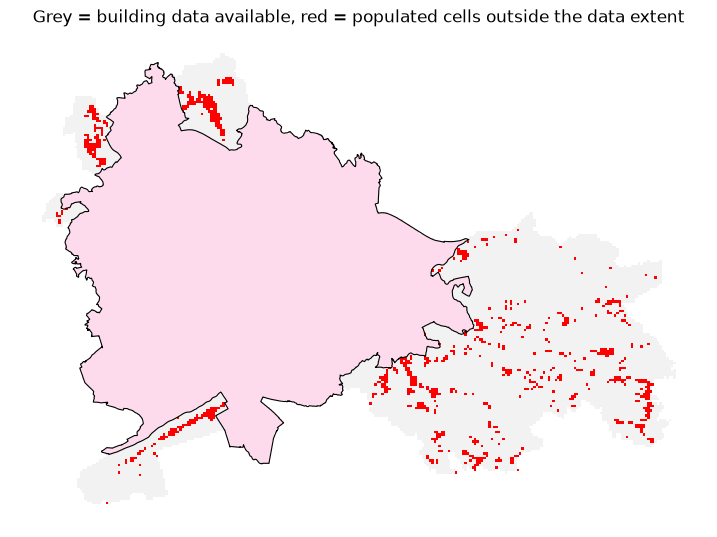

In [5]:
cells["bld_share_in_data"] = cells.geometry.intersection(extent.union_all()).area / CELL_AREA
cells["bld_in_data"] = cells["bld_share_in_data"] >= MIN_SHARE_IN_STUDY_AREA

n_in = cells["bld_in_data"].sum()
missed = cells["populated"] & ~cells["bld_in_data"]
print(f"Cells with building data: {n_in:,} of {len(cells):,}")
print(f"Populated cells WITHOUT building data: {missed.sum()} ({cells.loc[missed, 'pop'].sum():,.0f} residents)")

ax = cells.plot(column="bld_in_data", cmap="Pastel1_r", figsize=(9, 7), linewidth=0)
extent.boundary.plot(ax=ax, color="black", linewidth=0.8)
cells[missed].plot(ax=ax, color="red", linewidth=0, markersize=1)
ax.set_title("Grey = building data available, red = populated cells outside the data extent")
ax.set_axis_off()
plt.show()

## 6. Cut buildings along cell borders
A building often lies across two or more cells. If we assigned it whole to one cell, the coverage of that cell would be too high and its neighbour's too low.

So we **cut every footprint along the grid lines** (`overlay` with `intersection`). Each piece remembers its building's height and type, and belongs to exactly one cell.
Areas and floor areas are then summed from the pieces.

In [6]:
grid_in = cells.loc[cells["bld_in_data"], ["cell_id", "geometry"]]
pieces = gpd.overlay(
    bld[["id", "area_m2", "height", "floors_est", "residential", "geometry"]],
    grid_in,
    how="intersection",
    keep_geom_type=True,
)
pieces["piece_area"] = pieces.area
print(f"{len(bld):,} buildings -> {len(pieces):,} pieces")

# Sanity check: pieces in covered cells should add up to (almost) all building area
print(f"Footprint area kept: {pieces['piece_area'].sum() / bld.area.sum():.1%}")

75,061 buildings -> 96,351 pieces
Footprint area kept: 100.0%


## 7. Indicators from the pieces
- **coverage** = sum of piece areas / 10,000 m²
- **height** = average height, where large footprints count more than small ones (area-weighted). A cell with one 20 m block and three garden sheds is a 20 m place, not a 6 m place.
- **FAR** = sum of (piece area × floors) / 10,000 m². FAR 1 means as much floor space as land, e.g. a single storey covering the whole cell, or 4 storeys covering a quarter of it.
- **residential share** = residential piece area / all piece area

In [7]:
pieces["floor_area"] = pieces["piece_area"] * pieces["floors_est"]
pieces["height_x_area"] = pieces["height"] * pieces["piece_area"]
pieces["res_area"] = pieces["piece_area"] * pieces["residential"]

per_cell = pieces.groupby("cell_id").agg(
    built_area=("piece_area", "sum"),
    floor_area=("floor_area", "sum"),
    height_x_area=("height_x_area", "sum"),
    res_area=("res_area", "sum"),
)
ind = pd.DataFrame({
    # Overlapping footprints (0.2% of area) can push a few cells slightly above 1
    "bld_coverage": (per_cell["built_area"] / CELL_AREA).clip(upper=1),
    "bld_height": per_cell["height_x_area"] / per_cell["built_area"],
    "bld_far": per_cell["floor_area"] / CELL_AREA,
    "bld_residential_share": per_cell["res_area"] / per_cell["built_area"],
})
ind.head()

,bld_coverage,bld_height,bld_far,bld_residential_share
cell_id,,,,
SIHM100_4554_1037,0.014622,7.708061,0.036702,1.0
SIHM100_4554_1038,0.003664,4.500000,0.007329,1.0
SIHM100_4557_1031,0.002099,4.500000,0.004198,0.0
SIHM100_4559_1041,0.014304,10.200000,0.042912,1.0
SIHM100_4559_1042,0.017898,10.200000,0.053693,1.0


**Count and typical footprint** use the *whole building*, not the piece: a large hall that reaches into a cell makes that cell a "large-footprint" place, even if only part of it lies there.
Each building with a part in the cell is counted once (a building crossing 3 cells counts in all 3).

In [8]:
whole = pieces.drop_duplicates(["cell_id", "id"])
by_building = whole.groupby("cell_id").agg(
    bld_count=("id", "size"),
    bld_footprint_median=("area_m2", "median"),
)
by_building.head()

,bld_count,bld_footprint_median
cell_id,,
SIHM100_4554_1037,2,73.1
SIHM100_4554_1038,1,36.6
SIHM100_4557_1031,1,21.0
SIHM100_4559_1041,1,322.0
SIHM100_4559_1042,1,322.0


## 8. Combine and handle empty cells
- covered cell with no buildings: count, coverage, FAR, height = 0. Footprint and residential share stay NaN, because they are undefined without buildings.
- cell outside the data extent: everything NaN

Setting height to 0 for empty cells is a choice: "nothing built" is a real and meaningful state for clustering (fields, parks, forest).

In [9]:
result = cells[["cell_id", "bld_in_data", "bld_share_in_data"]].set_index("cell_id")
result = result.join(ind).join(by_building)

covered = result["bld_in_data"]
for col in ["bld_count", "bld_coverage", "bld_far", "bld_height"]:
    result.loc[covered, col] = result.loc[covered, col].fillna(0)
result["bld_count"] = result["bld_count"].astype("Int64")

cols = ["bld_count", "bld_coverage", "bld_height", "bld_far", "bld_footprint_median", "bld_residential_share"]
print(result.loc[covered, cols].describe().round(2).T)

                         count    mean      std  min   25%     50%     75%  \
bld_count              16369.0    5.89    10.06  0.0   0.0     1.0     8.0   
bld_coverage           16369.0    0.08     0.13  0.0   0.0     0.0    0.13   
bld_height             16369.0    4.64     6.09  0.0   0.0     2.1    7.93   
bld_far                16369.0     0.3     0.71  0.0   0.0     0.0    0.35   
bld_footprint_median    8207.0  732.54  4620.12  3.0  67.4  105.55  215.55   
bld_residential_share   8207.0    0.53      0.4  0.0   0.0    0.69     0.9   

                            max  
bld_count                 100.0  
bld_coverage                1.0  
bld_height                 77.0  
bld_far                   14.47  
bld_footprint_median   100133.9  
bld_residential_share       1.0  


## 9. Sanity checks
- coverage must be between 0 and 1 (capped above, because of overlapping footprints)
- populated cells should almost always have buildings
- the densest cells (highest FAR) should be places we recognise. When this was first run, the top ones were Trg republike (towers + Cankarjev dom) and BTC (Crystal Palace)

In [10]:
print(f"Coverage range: {result['bld_coverage'].min():.3f} – {result['bld_coverage'].max():.3f}")

pop_cov = cells.set_index("cell_id").loc[covered[covered].index]
no_bld = pop_cov["populated"] & (result.loc[pop_cov.index, "bld_count"] == 0)
print(f"Populated cells with building data but no building: {no_bld.sum()} of {pop_cov['populated'].sum():,}")

print("\nTop 10 cells by FAR:")
top = result.nlargest(10, "bld_far")[cols].join(cells.set_index("cell_id")[["E", "N"]])
top.round(2)

Coverage range: 0.000 – 1.000


Populated cells with building data but no building: 3 of 4,959

Top 10 cells by FAR:


,bld_count,bld_coverage,bld_height,bld_far,bld_footprint_median,bld_residential_share,E,N
cell_id,,,,,,,,
SIHM100_4613_1012,6,0.92,47.43,14.47,5212.40,0.00,461300,101200
SIHM100_4645_1030,5,0.50,73.09,11.91,624.00,0.00,464500,103000
SIHM100_4624_1048,8,0.68,52.41,11.81,692.70,0.04,462400,104800
SIHM100_4602_1043,1,0.81,34.60,9.71,21323.00,1.00,460200,104300
SIHM100_4601_1042,4,0.84,32.67,9.49,2473.40,0.93,460100,104200
SIHM100_4612_1012,6,0.68,41.47,9.42,2177.50,0.00,461200,101200
SIHM100_4617_1016,8,0.81,34.01,9.24,1143.05,0.00,461700,101600
SIHM100_4617_1019,9,0.59,45.36,9.10,1154.80,0.53,461700,101900
SIHM100_4653_1027,1,0.88,30.30,8.80,16735.50,0.00,465300,102700


## 10. Maps
One map per indicator. Grey = outside the building data extent.

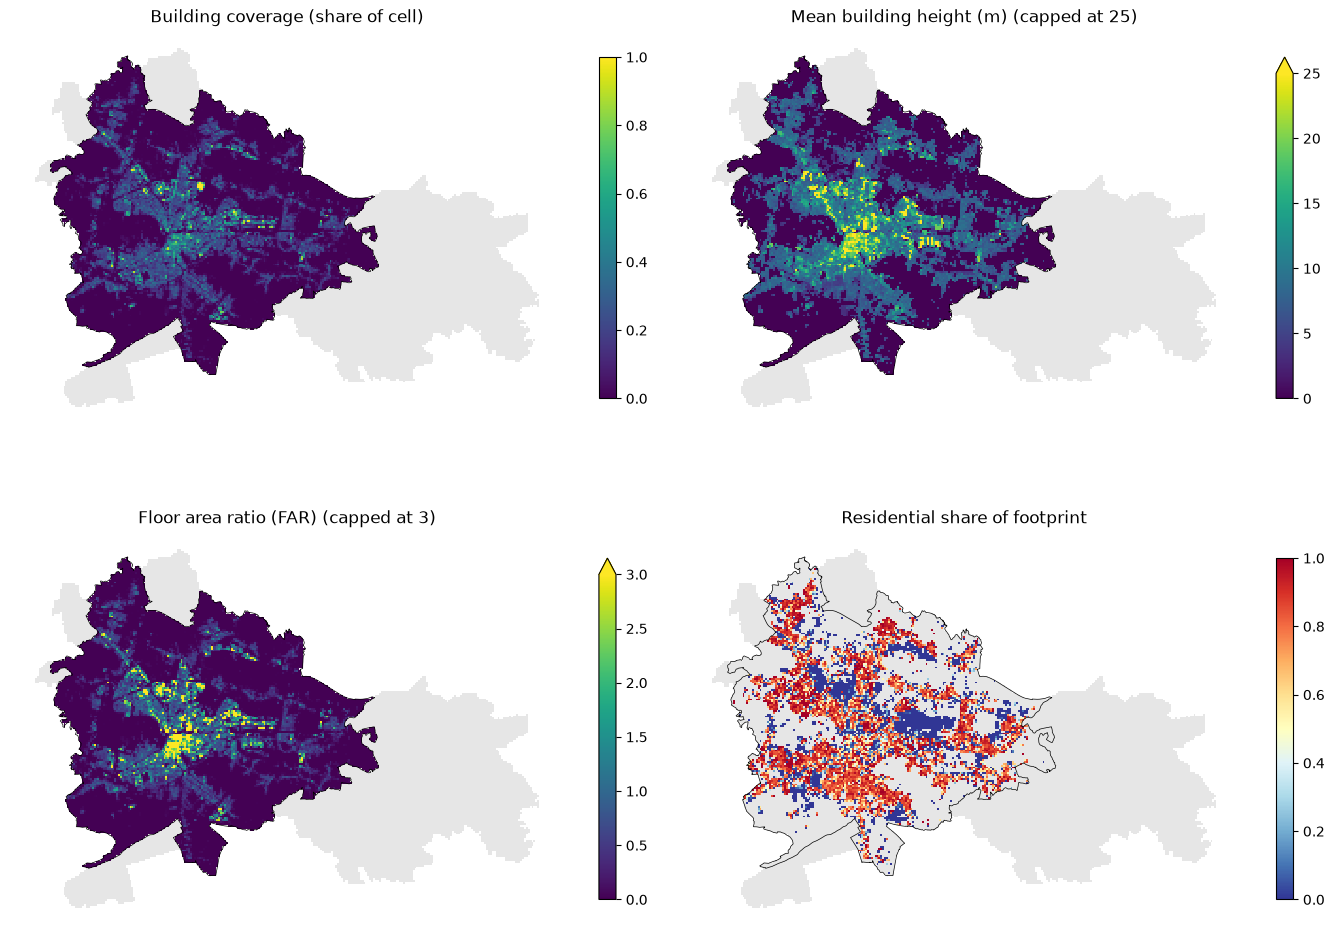

In [11]:
gdf = cells[["cell_id", "geometry"]].merge(result.reset_index(), on="cell_id")

maps = [
    ("bld_coverage", "Building coverage (share of cell)", "viridis", None),
    ("bld_height", "Mean building height (m)", "viridis", 25),
    ("bld_far", "Floor area ratio (FAR)", "viridis", 3),
    ("bld_residential_share", "Residential share of footprint", "RdYlBu_r", None),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (col, title, cmap, vmax) in zip(axes.flat, maps):
    gdf.plot(ax=ax, color="#e6e6e6", linewidth=0)
    gdf.dropna(subset=[col]).plot(ax=ax, column=col, cmap=cmap, vmax=vmax, linewidth=0,
                                  legend=True, legend_kwds={"shrink": 0.6})
    extent.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_title(title + (f" (capped at {vmax})" if vmax else ""))
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIGURES / "02_buildings.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. How do the indicators relate?
If two indicators are almost the same (correlation close to 1), clustering would count the same information twice.
This tells us which ones to keep or combine later (the plan's "PCA within correlated groups").

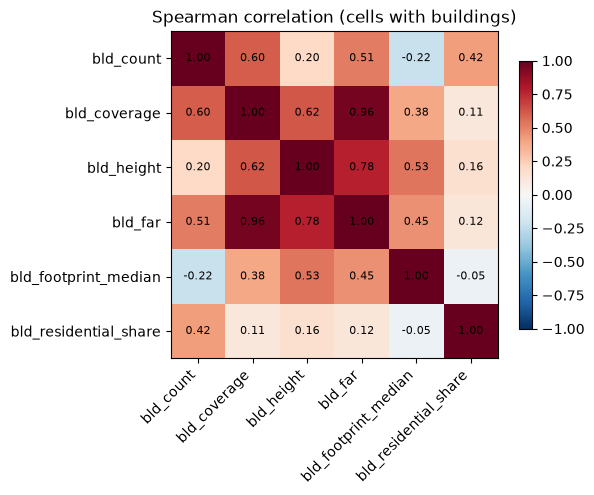

In [12]:
corr = result.loc[covered & (result["bld_count"] > 0), cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation (cells with buildings)")
plt.tight_layout()
plt.show()

## 12. Save

In [13]:
out = result[["bld_in_data", "bld_share_in_data"] + cols].reset_index()
out.to_csv(PROCESSED / "ind_buildings.csv", index=False)
print(f"Saved {len(out):,} rows to {PROCESSED / 'ind_buildings.csv'}")
out[out["bld_in_data"]].head()

Saved 27,505 rows to C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis\data\processed\ind_buildings.csv


,cell_id,bld_in_data,bld_share_in_data,bld_count,bld_coverage,bld_height,bld_far,bld_footprint_median,bld_residential_share
637,SIHM100_4635_946,True,0.815561,0,0.0,0.0,0.0,NaN,NaN
638,SIHM100_4636_946,True,0.681044,0,0.0,0.0,0.0,NaN,NaN
639,SIHM100_4637_946,True,0.680176,0,0.0,0.0,0.0,NaN,NaN
640,SIHM100_4638_946,True,0.511487,0,0.0,0.0,0.0,NaN,NaN
701,SIHM100_4634_947,True,0.984460,0,0.0,0.0,0.0,NaN,NaN


## Summary
- Six built-form indicators per cell, saved to `data/processed/ind_buildings.csv` (join to the grid on `cell_id`).
- Heights cleaned (13 impossible values), floors estimated from height, footprints cut along cell borders.

**Limitations to note in the thesis:**
- The data covers the settlement Ljubljana, not all of MOL. About 885 populated edge cells have no building data.
  → Ask Špela for the same extract clipped to **MOL** (EUBUCCO region SI041 covers it). This notebook will work unchanged with the new file.
- Building type is mostly model-estimated, so treat `bld_residential_share` as less certain.
- No building age → GURS cadastre (option B) if needed.

**Next:** imperviousness and vegetation (NDVI or canopy height).